> **Reentrenamiento:** ejecutar primero `Simulaciones_tiempos_fijos/baseline.ipynb` para recalibrar los cortes; luego esta notebook. Reinicia el kernel antes de correrla para cargar `coverage_min` y `coverage_window`.

# Q-Learning

s = (nvehicles, twaiting, lqueue, rarrival). Acciones: 12 duraciones de verde (5-60s).
Recompensa: multi-objetivo paper Electronics 2025 (sin clipping).

Configuracion:
- 5000 epocas, num_seconds=100000, delta_time=5
- Epsilon: 0.5 -> 0.05 con decay 0.9995 (por episodio)
- Sin clipping de recompensa
- Discretizador: 6/6/4/3 bins (432 estados posibles x 12 acciones = 5184 total)
- Q tabular con replay buffer 2000/64 (fuente)
- QLAgentConVisitas: tracking de visitas + early stopping dual (cobertura estable y meseta de recompensa)
- Guarda ultimo modelo

Nota: la Q-table y las salidas guardadas corresponden a la demanda anterior de 2334 vehículos y a una corrida sin semilla fija. Reentrenar con la ruta actual de 2410 vehículos y semilla 42 antes de usar esos resultados.

In [1]:
import os
os.environ["LIBSUMO_AS_TRACI"] = "1"

In [2]:
import argparse
import pandas as pd
import pickle
import sys
import numpy as np
import gymnasium as gym
from sumo_rl import SumoEnvironment
from sumo_rl.agents import QLAgent
from sumo_rl.exploration import EpsilonGreedy
import seaborn as sns
import matplotlib.pyplot as plt

Using libsumo as traci as requested by environment variable.


In [3]:
import pathlib as _pl, sys as _sys
_venv = _pl.Path(_sys.executable).resolve().parent.parent
_cand = _venv / "lib" / f"python{_sys.version_info.major}.{_sys.version_info.minor}" / "site-packages" / "sumo"
os.environ['SUMO_HOME'] = str(_cand) if _cand.exists() else "/home/santiago/Documentos/Tesis/.venv/lib/python3.14/site-packages/sumo"
tools = os.path.join(os.environ['SUMO_HOME'], 'tools')
sys.path.append(tools)

In [4]:
NET = os.path.join("..", "Simple_Intersection.net.xml")
ROU = os.path.join("..", "Distribuciones", "loja_intersection_weibull.rou.xml")
OUT_FOLDER = "resultados"

os.makedirs(OUT_FOLDER, exist_ok=True)

print(f"NET existe: {os.path.exists(NET)}")
print(f"ROU existe: {os.path.exists(ROU)}")

NET existe: True
ROU existe: True


## Reward

Recompensa multi-objetivo basada en:
"Comparative Evaluation of Fuzzy Logic and Q-Learning for Adaptive Urban
Traffic Signal Control" (Electronics 2025, 14, 2759)
https://www.mdpi.com/2079-9292/14/14/2759

Reward con 4 componentes:

Formula: `-2.0*waiting + 1.5*throughput + 3.0*improvement + congestion`

Componentes:
- `waiting`: tiempo promedio de espera por vehiculo (penaliza)
- `throughput`: vehiculos que salieron de la red en este step (recompensa)
- `improvement`: reducción en tiempo de espera vs step anterior (recompensa)
- `congestion`: penalización fuerte (-100) si waiting > 9s AND queue > 61

In [5]:
class Reward:
    def __init__(self):
        self._prev = {'waiting': 0.0, 'veh_ids': set()}

    def reset(self):
        self._prev = {'waiting': 0.0, 'veh_ids': set()}

    def __call__(self, ts):
        ids = ts.sumo.vehicle.getIDList()
        waiting_time = np.mean([ts.sumo.vehicle.getWaitingTime(v) for v in ids]) if len(ids) > 0 else 0.0
        veh_ids_actuales = set(v for lane in ts.lanes for v in ts.sumo.lane.getLastStepVehicleIDs(lane))
        throughput = len(self._prev['veh_ids'] - veh_ids_actuales)
        queue = ts.get_total_queued()

        improvement = self._prev['waiting'] - waiting_time
        congestion = -100.0 if (waiting_time > 9 and queue > 61) else 0.0

        self._prev = {'waiting': waiting_time, 'veh_ids': veh_ids_actuales}
        return -2.0 * waiting_time + 1.5 * throughput + 3.0 * improvement + congestion

## VariableGreenWrapper

Seleccion de duracion de verde (5-60s en pasos de 5s) = 12 acciones.

Referencia:
- Paper original usa duraciones fijas de 45s. Este wrapper permite al agente
  seleccionar entre 12 duraciones (5, 10, 15, ..., 60 segundos).
- El wrapper alterna fases internamente (1 - fase_actual) y acumula
  recompensa durante la duracion seleccionada.

Por que 5-60s:
- Minimo 5s: tiempo minimo util para un ciclo de semaforo
- Maximo 60s: limite razonable para no bloquear interseccion
- Paso de 5s: balance entre granularidad y espacio de acciones

In [6]:
class VariableGreenWrapper(gym.Wrapper):
    DURACIONES = list(range(5, 65, 5))  # 12 acciones: 5-60s

    def __init__(self, env, delta_time=5):
        super().__init__(env)
        self.delta_time = delta_time
        self.action_space = gym.spaces.Discrete(len(self.DURACIONES))
        self._fase_actual = 0

    def step(self, action_idx):
        duracion = self.DURACIONES[action_idx]
        n_pasos = duracion // self.delta_time
        reward_acumulado = 0.0
        terminated = truncated = False
        info = {}
        for _ in range(n_pasos):
            obs, reward, terminated, truncated, info = self.env.step(self._fase_actual)
            reward_acumulado += reward
            if terminated or truncated:
                break
            if self.env.unwrapped.sumo.simulation.getMinExpectedNumber() == 0:
                break
        self._fase_actual = 1 - self._fase_actual
        return obs, reward_acumulado, terminated, truncated, info

    def reset(self, **kwargs):
        self._fase_actual = 0
        return self.env.reset(**kwargs)

## QLAgentConVisitas

Agente Q-Learning clasico + tracking de visitas para analisis de cobertura.
Inicializacion dinamica de Q en 0.0 para estados no vistos. Update TD 1-step via `QLAgent.learn()`.


In [7]:
class QLAgentConVisitas(QLAgent):
    """Q-Learning tabular con Replay Buffer (2000/64). Update por minilotes."""
    BUFFER_CAP = 2000
    BATCH_SIZE = 64

    def __init__(self, starting_state, state_space, action_space,
                 alpha, gamma, exploration_strategy):
        ss = tuple(starting_state) if hasattr(starting_state, '__iter__') and not isinstance(starting_state, str) else starting_state
        super().__init__(ss, state_space, action_space,
                         alpha, gamma, exploration_strategy)
        self.visitas = {}
        self.replay = []

    def _ensure_state_in_qtable(self, state):
        s = tuple(state) if hasattr(state, '__iter__') and not isinstance(state, str) else state
        if s not in self.q_table:
            self.q_table[s] = [0.0] * self.action_space.n
        return s

    def act(self):
        self._ensure_state_in_qtable(self.state)
        estado = tuple(self.state) if hasattr(self.state, '__iter__') and not isinstance(self.state, str) else self.state
        self.visitas[estado] = self.visitas.get(estado, 0) + 1
        return super().act()

    def _q_update(self, s, a, r, s1):
        self.q_table[s][a] += self.alpha * (
            r + self.gamma * max(self.q_table[s1]) - self.q_table[s][a])

    def learn(self, next_state, reward, done=False):
        s = self._ensure_state_in_qtable(self.state)
        s1 = self._ensure_state_in_qtable(next_state)
        self.replay.append((s, self.action, reward, s1))
        if len(self.replay) > self.BUFFER_CAP:
            self.replay.pop(0)
        if len(self.replay) >= self.BATCH_SIZE:
            idx = np.random.choice(len(self.replay), self.BATCH_SIZE, replace=False)
            for i in idx:
                bs, ba, br, bs1 = self.replay[int(i)]
                self._q_update(bs, ba, br, bs1)
        self.state = s1


## TrafficStateWrapper

Para la implementacion del agente Q-Learning Tabular, la formulacion del espacio de estados
requiere una discretizacion matematica rigurosa. A diferencia de las redes neuronales
profundas (DQN) que procesan variables continuas y generalizan patrones de entrada, el
algoritmo Q-Learning tradicional actualiza una matriz finita de valores estado-accion.
Un espacio de estados continuo o excesivamente particionado genera un crecimiento exponencial
de la matriz Q, impidiendo la convergencia del agente.

El codigo implementado en la clase TrafficStateWrapper emplea un enfoque de discretizacion
multidimensional estructurado de control semaforico. El estado
continuo del entorno se transforma mediante una envoltura de Gymnasium en una tupla discreta
de cuatro dimensiones St = (Nt, Wt, Qt, At), mapeada en un espacio discreto MultiDiscrete().

Componentes:
- Numero de vehiculos activos (Nt) [6 bins]: Cuantifica la densidad absoluta del entorno
  evaluando la lista de identificadores vehiculares en curso. La division en 6 intervalos
  captura las transiciones de densidad, diferenciando los flujos bajos donde cambios minimos
  afectan el trafico, de los escenarios de alto volumen.
- Tiempo de espera promedio (Wt) [6 bins]: Calcula la media del tiempo de espera de los
  vehiculos activos. Esta resolucion de 6 categorias provee resolucion suficiente para
  detectar cruces de umbrales criticos en la demora vehicular sin expandir el estado.
- Longitud de cola (Qt) [4 bins]: Mide la congestion fisica registrando los vehiculos
  detenidos (umbral de velocidad < 0.1 m/s). La discretizacion en 4 niveles sintetiza de
  forma efectiva la dinamica espacial de acumulacion en los carriles.
- Tasa de llegada (At) [3 bins]: Calcula el flujo de ingreso vehicular mediante una ventana
  de tiempo movil de 30 segundos, correspondiente a 6 pasos de simulacion (delta_time de
  5 segundos). Restringirlo a 3 bins minimiza representaciones redundantes ante llegadas
  estocasticas.

La matriz parametrica de 6x6x4x3 limita el tamano del entorno a exactamente 432 estados
discretos. Evaluaciones empiricas en la literatura demuestran que configuraciones de mayor
granularidad (como 8/8/6/5 bins) incrementan el espacio en mas de un 300%, penalizando
drasticamente la tasa de convergencia del aprendizaje sin otorgar ventajas significativas
en el control. Esta topologia dimensional constituye el punto de equilibrio optimo entre
la captura de dinamicas de trafico complejas y la eficiencia computacional.

Calibracion de bin edges:
- Los limites numericos de particion no se programan de manera estatica.
- Se aplican los valores parametricos guardados en bin_edges_calibrados.npz,
  extraidos estadisticamente a partir de los percentiles de distribucion de la
  simulacion de linea base (tiempos fijos).
- En cada iteracion temporal, la funcion np.digitize mapea las variables continuas
  extraidas de la API de TraCI hacia estos indices calibrados.
- Este metodo garantiza que las fronteras de discretizacion esten matematicamente
  adaptadas a la demanda especifica de la interseccion evaluada en Loja.

Referencia:
- Comparative Evaluation of Fuzzy Logic and Q-Learning for Adaptive Urban Traffic
  Signal Control (Electronics 2025, 14, 2759)
  https://www.mdpi.com/2079-9292/14/14/2759
- A Deep Adaptive Traffic Signal Controller With Long-Term Planning Horizon and
  Spatial-Temporal State Definition Under Dynamic Traffic Fluctuations
  https://doi.org/10.3390/app14041531

In [8]:
_edges = np.load("../Simulaciones_tiempos_fijos/resultados/bin_edges_calibrados.npz")
EDGES_NVEHICULOS = _edges["nvehiculos"]
EDGES_WAITING    = _edges["waiting"]
EDGES_QUEUE      = _edges["queue"]
EDGES_ARRIVAL    = _edges["arrival"]


class TrafficStateWrapper(gym.Wrapper):
    observation_space = gym.spaces.MultiDiscrete([6, 6, 4, 3])

    def __init__(self, env):
        super().__init__(env)
        self._seen_departures = {}

    def _compute_state(self):
        sumo = self.env.unwrapped.sumo
        sim_time = float(sumo.simulation.getTime())
        ids = sumo.vehicle.getIDList()
        for v in ids:
            self._seen_departures.setdefault(v, sim_time)
        self._seen_departures = {
            v: t for v, t in self._seen_departures.items()
            if sim_time - t <= 30
        }
        n_vehiculos = len(ids)
        waiting = np.mean([sumo.vehicle.getWaitingTime(v) for v in ids]) if n_vehiculos > 0 else 0.0
        queue = self.env.unwrapped.traffic_signals[self.env.unwrapped.ts_ids[0]].get_total_queued()
        arrival = float(sum(
            1 for t in self._seen_departures.values()
            if sim_time - 30 <= t <= sim_time
        ))

        bin_n = int(np.digitize(n_vehiculos, EDGES_NVEHICULOS))
        bin_w = int(np.digitize(waiting, EDGES_WAITING))
        bin_q = int(np.digitize(queue, EDGES_QUEUE))
        bin_a = int(np.digitize(arrival, EDGES_ARRIVAL))

        return (bin_n, bin_w, bin_q, bin_a)

    def reset(self, **kwargs):
        self._seen_departures = {}
        obs, info = self.env.reset(**kwargs)
        return self._compute_state(), info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        return self._compute_state(), reward, terminated, truncated, info


In [9]:
def get_args():
    """
    Parametros de entrenamiento Q-Learning con referencias bibliograficas.
    
    Referencias:
    - Comparative Evaluation of Fuzzy Logic and Q-Learning for Adaptive Urban Traffic
      Signal Control (Electronics 2025, 14, 2759)
    """
    prs = argparse.ArgumentParser(formatter_class=argparse.ArgumentDefaultsHelpFormatter)
    prs.add_argument("-route", dest="route", type=str, default=ROU)
    prs.add_argument("-net", dest="net", type=str, default=NET)

    # Alpha (learning rate): tasa de aprendizaje para la actualizacion de la matriz Q.
    # Controla la magnitud de las actualizaciones de los valores estado-accion.
    # Ref: Comparative Evaluation of Fuzzy Logic and Q-Learning (2025)
    prs.add_argument("-a", dest="alpha", type=float, default=0.1)

    # Gamma (discount factor): factor de descuento para recompensas futuras.
    # Un valor de 0.95 prioriza recompensas a corto plazo manteniendo visibilidad
    # de consecuencias futuras en el trafico.
    # Ref: Comparative Evaluation of Fuzzy Logic and Q-Learning (2025)
    prs.add_argument("-g", dest="gamma", type=float, default=0.95)
    prs.add_argument("-gui", action="store_true", default=False)
    prs.add_argument("-r", dest="reward", type=str, default='paper_2025')

    # Runs: numero de ejecuciones independientes del experimento.
    prs.add_argument("-runs", dest="runs", type=int, default=1)
    prs.add_argument("-seed", dest="seed", type=int, default=42)

    # Episodes: 5000 episodios de entrenamiento.
    # Suficiente para alcanzar convergencia de la politica tabular clasica (TD de un paso con replay 2000/64).
    # Ref: Comparative Evaluation of Fuzzy Logic and Q-Learning (2025)
    prs.add_argument("-episodes", dest="episodes", type=int, default=5000)
    prs.add_argument("-num_seconds", dest="num_seconds", type=int, default=100000)

    # Min epsilon: umbral minimo de exploracion (5%).
    # Previene convergencia a optimos locales manteniendo adaptabilidad.
    prs.add_argument("-min_epsilon", dest="min_epsilon", type=float, default=0.05)

    # Initial epsilon: exploracion inicial al 50%.
    # Politica epsilon-greedy que guia desde exploracion hacia explotacion.
    prs.add_argument("-initial_epsilon", dest="initial_epsilon", type=float, default=0.5)

    # Decay: decaimiento de epsilon por episodio (0.9995).
    # Reduce exploracion gradualmente a lo largo de los 5000 episodios.
    prs.add_argument("-decay", dest="decay", type=float, default=0.9995)

    # Cobertura minima antes de permitir la parada temprana.
    prs.add_argument("-coverage_min", dest="coverage_min", type=float, default=0.50)
    prs.add_argument("-coverage_window", dest="coverage_window", type=int, default=10)
    return prs.parse_args(args=[])

In [10]:
if __name__ == '__main__':
    if 'args' not in dir() or not hasattr(args, 'seed'):
        args = get_args()

    np.random.seed(args.seed)

    exploracion = EpsilonGreedy(
        initial_epsilon=args.initial_epsilon,
        min_epsilon=args.min_epsilon,
        decay=1.0  # sin decay interno, solo el loop controla por episodio
    )

    reward_fn = Reward()

    import sys as _sys
    import os as _os

    historial_recompensas = []
    cobertura_historial = []
    media_recompensa_historial = []  # media por bloque de 100 episodios

    def cobertura_estabilizada(historial):
        ventana = args.coverage_window
        return (
            len(historial) >= ventana
            and historial[-1] >= args.coverage_min
            and historial[-1] <= historial[-ventana]
        )

    def meseta_recompensa(historial, tol=0.05):
        # meseta si la media del ultimo bloque varia menos de tol respecto al anterior
        if len(historial) < 2:
            return False
        return abs(historial[-1] - historial[-2]) <= tol * max(1.0, abs(historial[-2]))

    print(f"Entrenamiento Q-Learning | cobertura objetivo: {args.coverage_min:.0%} | ventana: {args.coverage_window} bloques")
    for run in range(1, args.runs + 1):
        for episode in range(1, args.episodes + 1):
            reward_fn.reset()

            _old_stderr = _sys.stderr
            _sys.stderr = open(_os.devnull, 'w')

            env = SumoEnvironment(
                net_file=args.net,
                route_file=args.route,
                out_csv_name="temp",
                single_agent=True,
                use_gui=args.gui,
                num_seconds=args.num_seconds,
                delta_time=5,
                yellow_time=3,
                min_green=5,
                reward_fn=reward_fn,
                time_to_teleport=-1,
                sumo_seed=args.seed,
                additional_sumo_cmd="-W --no-step-log"
            )

            _sys.stderr = _old_stderr

            env = VariableGreenWrapper(env, delta_time=5)
            env = TrafficStateWrapper(env)
            obs, _ = env.reset(seed=args.seed)

            if episode == 1 and run == 1:
                agente = QLAgentConVisitas(
                    starting_state=obs,
                    state_space=env.observation_space,
                    action_space=env.action_space,
                    alpha=args.alpha,
                    gamma=args.gamma,
                    exploration_strategy=exploracion,
                )

            try:
                agente.state = obs
                agente.action_space.seed(args.seed + episode - 1)
                done = False
                recompensa_episodio = 0

                tiempo_final = 0
                while not done:
                    accion = agente.act()
                    next_obs, reward, terminated, truncated, info = env.step(accion)

                    agente.learn(next_state=next_obs, reward=reward, done=terminated)
                    recompensa_episodio += reward

                    if env.unwrapped.sumo.simulation.getMinExpectedNumber() == 0:
                        tiempo_final = env.unwrapped.sim_step
                        break

                    done = terminated or truncated

                historial_recompensas.append(recompensa_episodio)

            finally:
                env.close()

            exploracion.epsilon = max(exploracion.epsilon * args.decay, args.min_epsilon)

            if episode % 100 == 0:
                cobertura = len(agente.q_table) / (6 * 6 * 4 * 3)
                cobertura_historial.append(cobertura)
                media_bloque = float(np.mean(historial_recompensas[-100:]))
                media_recompensa_historial.append(media_bloque)
                print(f"  Ep {episode:03d} | Rec: {recompensa_episodio:10.2f} | Epsilon: {exploracion.epsilon:.3f} | Vaciado: {tiempo_final:.0f}s | Cobertura: {cobertura:.1%} | Media100: {media_bloque:.1f}")
            else:
                print(f"  Ep {episode:03d} | Rec: {recompensa_episodio:10.2f} | Epsilon: {exploracion.epsilon:.3f} | Vaciado: {tiempo_final:.0f}s")

            if cobertura_estabilizada(cobertura_historial) and meseta_recompensa(media_recompensa_historial):
                print(f"Convergencia dual (cobertura + meseta de recompensa) en episodio {episode} - deteniendo entrenamiento")
                break

    with open(os.path.join(OUT_FOLDER, "qlearning.pkl"), 'wb') as f:
        pickle.dump(agente.q_table, f)
    print(f"\nModelo guardado en {os.path.join(OUT_FOLDER, 'qlearning.pkl')}")

    # Estadisticas del entrenamiento
    print("\n" + "="*60)
    print("ESTADISTICAS DEL ENTRENAMIENTO")
    print("="*60)
    print(f"Estados en Q-table: {len(agente.q_table)}")
    print(f"Total estados posibles: {6*6*4*3} (bins 6/6/4/3, independiente de las 12 acciones)")
    print(f"Cobertura final: {len(agente.q_table)/(6*6*4*3):.1%}")
    print(f"\nTop 10 estados mas visitados:")
    top_visitados = sorted(agente.visitas.items(), key=lambda x: x[1], reverse=True)[:10]
    for estado, visits in top_visitados:
        print(f"  {estado}: {visits} visitas")


    # Limpiar CSVs temporales de entrenamiento
    import glob as _glob
    for _f in _glob.glob("temp_*.csv"):
        os.remove(_f)

Entrenamiento Q-Learning | cobertura objetivo: 50% | ventana: 10 bloques
  Ep 001 | Rec:   -9523.53 | Epsilon: 0.500 | Vaciado: 3930s
  Ep 002 | Rec:   -7857.09 | Epsilon: 0.500 | Vaciado: 3840s
  Ep 003 | Rec:  -11354.38 | Epsilon: 0.499 | Vaciado: 4055s
  Ep 004 | Rec:   -9424.37 | Epsilon: 0.499 | Vaciado: 3945s
  Ep 005 | Rec:   -8988.69 | Epsilon: 0.499 | Vaciado: 3830s
  Ep 006 | Rec:   -9767.37 | Epsilon: 0.499 | Vaciado: 4015s
  Ep 007 | Rec:   -8456.18 | Epsilon: 0.498 | Vaciado: 4295s
  Ep 008 | Rec:   -6679.43 | Epsilon: 0.498 | Vaciado: 3920s
  Ep 009 | Rec:   -8016.08 | Epsilon: 0.498 | Vaciado: 4080s
  Ep 010 | Rec:   -6599.04 | Epsilon: 0.498 | Vaciado: 4040s
  Ep 011 | Rec:   -8720.75 | Epsilon: 0.497 | Vaciado: 4180s
  Ep 012 | Rec:  -10052.74 | Epsilon: 0.497 | Vaciado: 4135s
  Ep 013 | Rec:   -8054.09 | Epsilon: 0.497 | Vaciado: 4010s
  Ep 014 | Rec:   -6702.78 | Epsilon: 0.497 | Vaciado: 3820s
  Ep 015 | Rec:   -6997.46 | Epsilon: 0.496 | Vaciado: 3990s
  Ep 016 | R

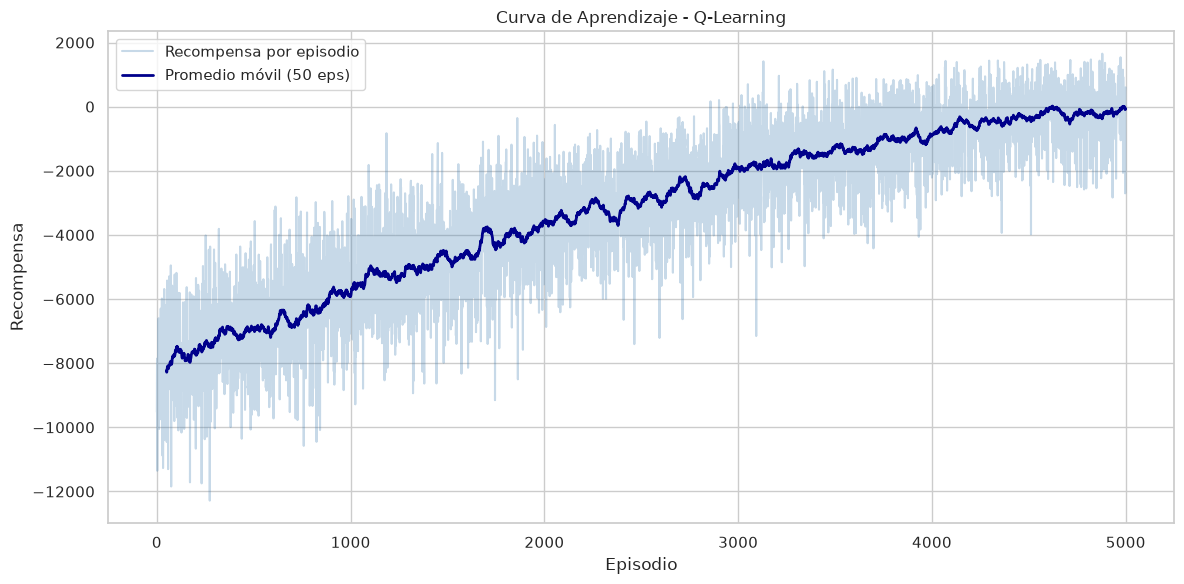

In [11]:
# Curva de Aprendizaje
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))
plt.plot(historial_recompensas, alpha=0.3, label="Recompensa por episodio", color="steelblue")

# Promedio móvil
if len(historial_recompensas) >= 50:
    window = 50
    promedio_movil = pd.Series(historial_recompensas).rolling(window=window).mean()
    plt.plot(promedio_movil, label=f"Promedio móvil ({window} eps)", color="darkblue", linewidth=2)

plt.xlabel("Episodio")
plt.ylabel("Recompensa")
plt.title("Curva de Aprendizaje - Q-Learning")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
args = get_args()
ruta_modelo = os.path.join(OUT_FOLDER, "qlearning.pkl")

print(f"Cargando modelo: {ruta_modelo}")
with open(ruta_modelo, 'rb') as f:
    q_table_entrenada = pickle.load(f)

print(f"Estados en Q-table: {len(q_table_entrenada)}")

# Configuracion de evaluacion
USAR_FALLBACK = False  # True: estados no vistos -> 30s | False: estados no vistos -> ultima accion

env_eval = SumoEnvironment(
    net_file=args.net,
    route_file=args.route,
    out_csv_name=os.path.join(OUT_FOLDER, "evaluacion_final"),
    single_agent=True,
    use_gui=False,
    num_seconds=args.num_seconds,
    delta_time=5,
    yellow_time=3,
    min_green=5,
    time_to_teleport=-1,
    sumo_seed=args.seed,
    additional_sumo_cmd=f"-W --no-step-log --tripinfo-output {os.path.join(OUT_FOLDER, 'tripinfo.xml')}"
)

env_eval = VariableGreenWrapper(env_eval, delta_time=5)
env_eval = TrafficStateWrapper(env_eval)

obs, _ = env_eval.reset(seed=args.seed)
try:

    exploracion_nula = EpsilonGreedy(initial_epsilon=0.0, min_epsilon=0.0, decay=1.0)
    agente_eval = QLAgentConVisitas(
        starting_state=obs,
        state_space=env_eval.observation_space,
        action_space=env_eval.action_space,
        alpha=0.0,
        gamma=args.gamma,
        exploration_strategy=exploracion_nula,
    )
    agente_eval.q_table = q_table_entrenada

    DURACIONES = VariableGreenWrapper.DURACIONES
    N_ACCIONES = len(DURACIONES)

    def elegir_accion(q_table, estado, n_acciones, ultima_accion):
        if estado in q_table:
            return int(np.argmax(q_table[estado]))
        if USAR_FALLBACK:
            return n_acciones // 2  # 30s: accion de emergencia
        return ultima_accion  # mantener ultima duracion

    modo = "FALLBACK (30s)" if USAR_FALLBACK else "ULTIMA ACCION"
    print(f"Ejecutando evaluacion en modo: {modo}")

    done = False
    ultima_accion = N_ACCIONES // 2  # inicial: 30s
    datos_recolectados = []

    while not done:
        estado_actual = tuple(agente_eval.state)
        accion = elegir_accion(agente_eval.q_table, estado_actual, N_ACCIONES, ultima_accion)
        ultima_accion = accion  # guardar para siguiente paso
        next_obs, reward, terminated, truncated, info = env_eval.step(accion)

        datos_recolectados.append(info)
        agente_eval.state = next_obs

        if env_eval.unwrapped.sumo.simulation.getMinExpectedNumber() == 0:
            tiempo_final = env_eval.unwrapped.sim_step
            print(f"Evaluacion completada. Red vaciada en {tiempo_final:.1f}s")
            break

        done = terminated or truncated

finally:
    env_eval.close()

df_metricas = pd.DataFrame(datos_recolectados)
ruta_csv = os.path.join(OUT_FOLDER, "metricas.csv")
os.makedirs(OUT_FOLDER, exist_ok=True)
df_metricas.to_csv(ruta_csv, index=False)

print(f"CSV exportado: {ruta_csv}")
print(f"XML generado: {os.path.join(OUT_FOLDER, 'tripinfo.xml')}")

Cargando modelo: resultados/qlearning.pkl
Estados en Q-table: 205
Ejecutando evaluacion en modo: ULTIMA ACCION
Evaluacion completada. Red vaciada en 4025.0s
CSV exportado: resultados/metricas.csv
XML generado: resultados/tripinfo.xml


In [13]:
df_metricas = pd.read_csv(os.path.join(OUT_FOLDER, "metricas.csv"))
print(f"Registros cargados: {len(df_metricas)}")

Registros cargados: 239


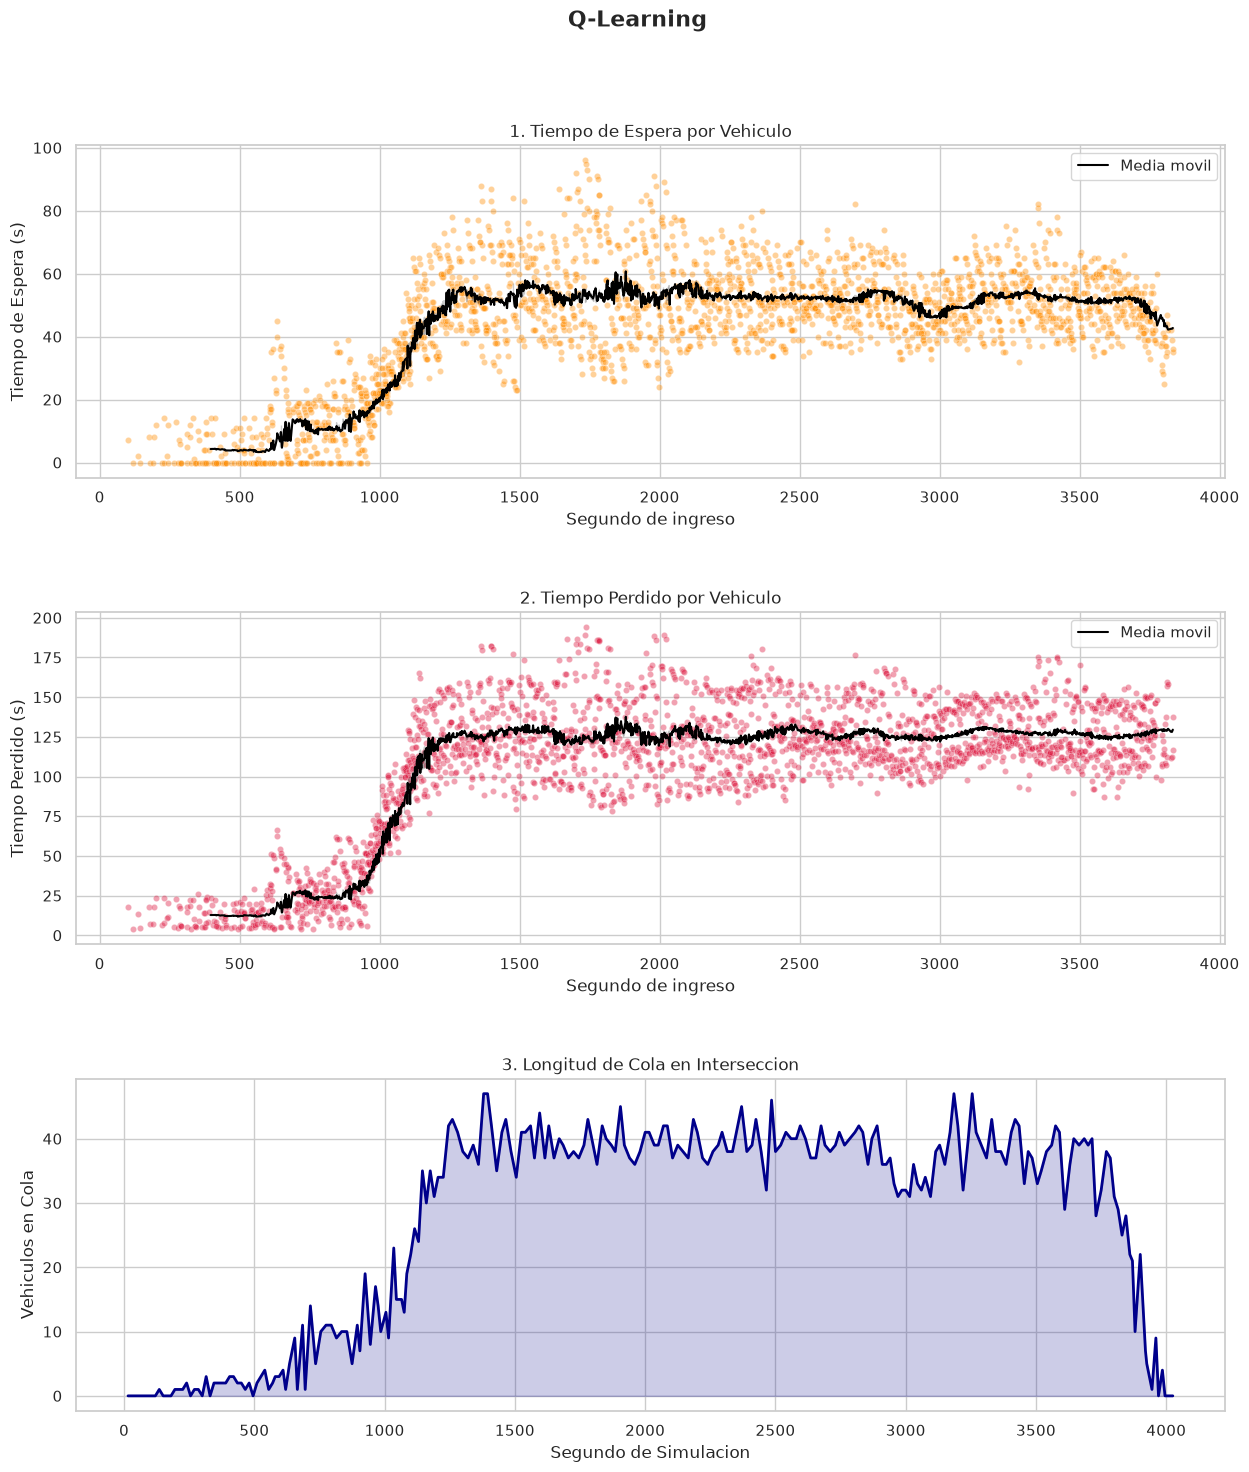

In [14]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

ruta_xml = os.path.join(OUT_FOLDER, "tripinfo.xml")
df_trips = pd.read_xml(ruta_xml)

for col in ['depart', 'waitingTime', 'timeLoss']:
    df_trips[col] = pd.to_numeric(df_trips[col])

fig, axs = plt.subplots(3, 1, figsize=(14, 15))
fig.tight_layout(pad=6.0)
fig.suptitle('Q-Learning', fontsize=16, fontweight='bold', y=1.02)

sns.scatterplot(x=df_trips['depart'], y=df_trips['waitingTime'], alpha=0.4, color='darkorange', s=20, ax=axs[0])
sns.lineplot(x=df_trips['depart'], y=df_trips['waitingTime'].rolling(50).mean(), color='black', label='Media movil', ax=axs[0])
axs[0].set_title("1. Tiempo de Espera por Vehiculo")
axs[0].set_xlabel("Segundo de ingreso")
axs[0].set_ylabel("Tiempo de Espera (s)")
axs[0].legend()

sns.scatterplot(x=df_trips['depart'], y=df_trips['timeLoss'], alpha=0.4, color='crimson', s=20, ax=axs[1])
sns.lineplot(x=df_trips['depart'], y=df_trips['timeLoss'].rolling(50).mean(), color='black', label='Media movil', ax=axs[1])
axs[1].set_title("2. Tiempo Perdido por Vehiculo")
axs[1].set_xlabel("Segundo de ingreso")
axs[1].set_ylabel("Tiempo Perdido (s)")
axs[1].legend()

axs[2].plot(df_metricas['step'], df_metricas['system_total_stopped'], color='darkblue', linewidth=2)
axs[2].fill_between(df_metricas['step'], df_metricas['system_total_stopped'], color='darkblue', alpha=0.2)
axs[2].set_title("3. Longitud de Cola en Interseccion")
axs[2].set_xlabel("Segundo de Simulacion")
axs[2].set_ylabel("Vehiculos en Cola")

plt.show()

In [15]:
for col in ['waitingTime', 'timeLoss', 'routeLength', 'duration']:
    df_trips[col] = pd.to_numeric(df_trips[col])

df_trips['velocidad_kmh'] = (df_trips['routeLength'] / df_trips['duration']) * 3.6

promedio_espera = df_trips['waitingTime'].mean()
maximo_espera = df_trips['waitingTime'].max()
promedio_perdido = df_trips['timeLoss'].mean()
maximo_perdido = df_trips['timeLoss'].max()
velocidad_media = df_trips['velocidad_kmh'].mean()
total_vehiculos = len(df_trips)
cola_promedio = df_metricas['system_total_stopped'].mean()
cola_maxima = df_metricas['system_total_stopped'].max()

print("=" * 50)
print("  REPORTE DE METRICAS Q-Learning")
print("=" * 50)
print("\n--- Rendimiento General ---")
print(f"Total de vehiculos procesados : {total_vehiculos}")
print(f"Velocidad promedio del sistema: {velocidad_media:.2f} km/h")

print("\n--- Demora Vehicular (Tripinfo) ---")
print(f"Tiempo de espera promedio     : {promedio_espera:.2f} s")
print(f"Tiempo de espera MAXIMO       : {maximo_espera:.2f} s")
print(f"Tiempo perdido promedio       : {promedio_perdido:.2f} s")
print(f"Tiempo perdido MAXIMO         : {maximo_perdido:.2f} s")

print("\n--- Ocupacion de la Interseccion (TraCI) ---")
print(f"Longitud de cola promedio     : {cola_promedio:.2f} vehiculos")
print(f"Longitud de cola MAXIMA       : {cola_maxima} vehiculos")
print("=" * 50)

display(df_trips[['id', 'depart', 'duration', 'waitingTime', 'timeLoss']].head())

  REPORTE DE METRICAS Q-Learning

--- Rendimiento General ---
Total de vehiculos procesados : 2410
Velocidad promedio del sistema: 15.79 km/h

--- Demora Vehicular (Tripinfo) ---
Tiempo de espera promedio     : 44.42 s
Tiempo de espera MAXIMO       : 96.00 s
Tiempo perdido promedio       : 108.33 s
Tiempo perdido MAXIMO         : 194.16 s

--- Ocupacion de la Interseccion (TraCI) ---
Longitud de cola promedio     : 26.60 vehiculos
Longitud de cola MAXIMA       : 47 vehiculos


,id,depart,duration,waitingTime,timeLoss
0,veh_0,101.0,64.0,7.0,17.57
1,veh_1,120.0,59.0,0.0,3.94
2,veh_2,137.0,58.0,2.0,13.35
3,veh_3,143.0,60.0,0.0,4.89
4,veh_5,178.0,57.0,0.0,6.91
